# Testing multiple machine learning approaches.

## Load packages

https://auto.gluon.ai/0.4.0/tutorials/tabular_prediction/tabular-quickstart.html

In [1]:
%pip install autogluon

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of statsforecast to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of fasttransform to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of python-fasthtml to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of python-fasthtml to determine which version is com

In [2]:
from autogluon.tabular import TabularDataset, TabularPredictor
import pandas as pd
import numpy as np

Connect to drive

In [3]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


Load the datasets

In [4]:
data = TabularDataset('/content/drive/Shareddrives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/foundation_model_embeddings_grassland_phase_detection/OutputTesseraEmbeddings/TS_3y_embeddings.csv')

#subsample_size = 500  # subsample subset of data for faster demo, try setting this to much larger values
#train_data = train_data.sample(n=subsample_size, random_state=0)
#data = data.loc[data['Level4'] != "nograss"]
data.head()

,Unnamed: 0,Level4,lon,lat,inventory_year,emb_2_0,emb_2_1,emb_2_2,emb_2_3,emb_2_4,...,emb_0_118,emb_0_119,emb_0_120,emb_0_121,emb_0_122,emb_0_123,emb_0_124,emb_0_125,emb_0_126,emb_0_127
0,1,F1_2,2.945650,50.829231,2019,0.882456,2.264970,2.088480,1.911988,-0.352982,...,-0.127724,0.095793,0.351240,-0.223517,-0.510895,0.127724,0.223517,1.277238,-0.415102,3.193095
1,2,F1_2,2.946892,50.829040,2019,0.205124,1.611689,2.930344,1.758207,-0.058607,...,-0.031203,-0.093609,0.187217,-0.156014,-0.624058,0.187217,0.280826,1.092101,-0.530449,2.995476
2,3,F1_2,2.948197,50.828701,2019,0.271635,1.478900,2.323986,1.539263,-0.754541,...,-0.336449,-0.168225,0.235514,0.370094,-0.471029,0.370094,0.100935,1.042992,-0.706543,2.826173
3,4,F1_2,2.948436,50.828369,2019,0.092612,1.111341,2.191812,0.185224,-0.864377,...,-0.089070,0.118760,0.148450,0.831318,-0.237519,0.029690,0.029690,1.514187,-0.475039,2.820543
4,5,F1_2,2.947491,50.828123,2019,0.626860,1.624137,2.678402,0.655354,-0.940290,...,0.058743,0.000000,0.146858,0.381830,-0.205601,0.146858,0.088115,1.409835,-0.469945,2.966527


In [5]:
type(data)

pandas.core.frame.DataFrame

In [6]:
test_data = data.loc[data['inventory_year'] == 2021]
train_data = data.loc[data['inventory_year'] != 2021]


test_data = test_data.drop(columns=['Unnamed: 0','lon','lat','inventory_year'])

train_data = train_data.drop(columns=['Unnamed: 0','lon','lat','inventory_year'])
train_data.head()


,Level4,emb_2_0,emb_2_1,emb_2_2,emb_2_3,emb_2_4,emb_2_5,emb_2_6,emb_2_7,emb_2_8,...,emb_0_118,emb_0_119,emb_0_120,emb_0_121,emb_0_122,emb_0_123,emb_0_124,emb_0_125,emb_0_126,emb_0_127
0,F1_2,0.882456,2.264970,2.088480,1.911988,-0.352982,-0.500058,3.735731,0.117661,-0.794211,...,-0.127724,0.095793,0.351240,-0.223517,-0.510895,0.127724,0.223517,1.277238,-0.415102,3.193095
1,F1_2,0.205124,1.611689,2.930344,1.758207,-0.058607,-0.703283,3.018255,-1.377262,-0.615372,...,-0.031203,-0.093609,0.187217,-0.156014,-0.624058,0.187217,0.280826,1.092101,-0.530449,2.995476
2,F1_2,0.271635,1.478900,2.323986,1.539263,-0.754541,-0.573451,3.440706,0.030182,-0.513088,...,-0.336449,-0.168225,0.235514,0.370094,-0.471029,0.370094,0.100935,1.042992,-0.706543,2.826173
3,F1_2,0.092612,1.111341,2.191812,0.185224,-0.864377,-0.617412,3.148800,-0.154353,-0.308706,...,-0.089070,0.118760,0.148450,0.831318,-0.237519,0.029690,0.029690,1.514187,-0.475039,2.820543
4,F1_2,0.626860,1.624137,2.678402,0.655354,-0.940290,-0.227949,3.162794,0.056987,-0.769328,...,0.058743,0.000000,0.146858,0.381830,-0.205601,0.146858,0.088115,1.409835,-0.469945,2.966527


In [7]:
test_data.head()

,Level4,emb_2_0,emb_2_1,emb_2_2,emb_2_3,emb_2_4,emb_2_5,emb_2_6,emb_2_7,emb_2_8,...,emb_0_118,emb_0_119,emb_0_120,emb_0_121,emb_0_122,emb_0_123,emb_0_124,emb_0_125,emb_0_126,emb_0_127
18314,F1_2,-0.216589,0.928239,2.630012,2.042127,0.464120,-1.825537,3.929547,-0.495061,1.113887,...,0.208021,-0.356607,-0.059435,-0.029717,0.297173,0.000000,0.148586,1.129256,-0.178304,2.971726
18315,F1_2,0.696972,1.103538,2.497482,1.219701,-0.638891,-0.435607,3.630061,-0.058081,-0.987377,...,-0.119543,-0.149429,0.298858,0.777031,0.268972,0.478173,-0.747145,1.075889,0.119543,2.749495
18316,F1_2,0.578505,1.388413,2.863601,0.578505,-0.028925,-1.359487,3.413181,0.491730,-0.723132,...,-0.116602,-0.029150,0.058301,0.583008,0.262354,0.349805,0.145752,1.107715,-0.174902,2.769289
18317,F1_2,0.318514,0.579116,3.416787,0.550161,0.115823,-0.608072,2.634980,0.521205,-0.376426,...,-0.751158,0.030046,0.510787,0.270417,0.120185,0.210324,-0.600926,1.622500,-0.691065,3.004631
18318,F1_2,0.503163,1.272706,2.338228,1.864663,-0.088793,-1.035924,3.137369,0.384772,0.236783,...,-0.063404,-0.126808,-0.031702,0.285319,0.221915,0.253617,-0.348723,1.743615,-0.095106,2.916592


In [8]:
label = 'Level4'
print("Summary of class variable: \n", train_data[label].describe())

Summary of class variable: 
 count     24604
unique        6
top          F3
freq       7234
Name: Level4, dtype: object


## Naïve approach: not taking spatial autocorrelation into account.

In [9]:
save_path = '/content/drive/Shareddrives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/foundation_model_embeddings_grassland_phase_detection/AutoML_Tessera_prediction_output_3yr/'  # specifies folder to store trained models
#predictor = TabularPredictor(label=label, path=save_path).fit(train_data,num_gpus=1)
label = 'Level4'
TabularPredictor(label=label, path=save_path,eval_metric='f1_macro').fit(train_data,calibrate_decision_threshold=True)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.18
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Oct 22 03:07:54 UTC 2026
CPU Count:          2
Pytorch Version:    2.11.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       10.96 GB / 12.67 GB (86.5%)
Disk Space Avail:   81.46 GB / 107.72 GB (75.6%)
No presets specified! To achieve strong results with AutoGluon, it is recommended to use the available presets. Defaulting to `'medium'`...
	Recommended Presets (For more details refer to https://auto.gluon.ai/stable/tutorials/tabular/tabular-essentials.html#presets):
	presets='extreme'  : Use this if you have a GPU. The go-to preset for best results, and the one to use for benchmark comparisons. New in v1.6: far better than 'best' on datasets <100000 samples by using Tabular Foundation Models (TFMs) meta-learned on https://tabarena.ai: Nori, TabICLv2, an

In [10]:
label = 'Level4'
y_test = test_data[label]  # values to predict
test_data_nolab = test_data.drop(columns=[label])  # delete label column to prove we're not cheating
test_data_nolab.head()

,emb_2_0,emb_2_1,emb_2_2,emb_2_3,emb_2_4,emb_2_5,emb_2_6,emb_2_7,emb_2_8,emb_2_9,...,emb_0_118,emb_0_119,emb_0_120,emb_0_121,emb_0_122,emb_0_123,emb_0_124,emb_0_125,emb_0_126,emb_0_127
18314,-0.216589,0.928239,2.630012,2.042127,0.464120,-1.825537,3.929547,-0.495061,1.113887,2.227774,...,0.208021,-0.356607,-0.059435,-0.029717,0.297173,0.000000,0.148586,1.129256,-0.178304,2.971726
18315,0.696972,1.103538,2.497482,1.219701,-0.638891,-0.435607,3.630061,-0.058081,-0.987377,1.393943,...,-0.119543,-0.149429,0.298858,0.777031,0.268972,0.478173,-0.747145,1.075889,0.119543,2.749495
18316,0.578505,1.388413,2.863601,0.578505,-0.028925,-1.359487,3.413181,0.491730,-0.723132,1.301637,...,-0.116602,-0.029150,0.058301,0.583008,0.262354,0.349805,0.145752,1.107715,-0.174902,2.769289
18317,0.318514,0.579116,3.416787,0.550161,0.115823,-0.608072,2.634980,0.521205,-0.376426,1.563614,...,-0.751158,0.030046,0.510787,0.270417,0.120185,0.210324,-0.600926,1.622500,-0.691065,3.004631
18318,0.503163,1.272706,2.338228,1.864663,-0.088793,-1.035924,3.137369,0.384772,0.236783,1.420695,...,-0.063404,-0.126808,-0.031702,0.285319,0.221915,0.253617,-0.348723,1.743615,-0.095106,2.916592


In [11]:
predictor = TabularPredictor.load(save_path)  # unnecessary, just demonstrates how to load previously-trained predictor from file

y_pred = predictor.predict(test_data_nolab)
print("Predictions:  \n", y_pred)
perf = predictor.evaluate_predictions(y_true=y_test, y_pred=y_pred, auxiliary_metrics=True)

Predictions:  
 18314    nograss
18315       F1_2
18316       F1_2
18317       F1_2
18318       F1_2
          ...   
27027    nograss
27028    nograss
27029    nograss
27030         F3
27031    nograss
Name: Level4, Length: 8718, dtype: object


In [12]:
perf

{'f1_macro': 0.5112731075561818,
 'accuracy': 0.5805230557467309,
 'balanced_accuracy': np.float64(0.4856677734578154),
 'mcc': np.float64(0.4412100469184322)}

In [13]:
predictor.leaderboard(test_data, silent=True)

,model,score_test,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,LightGBMXT,0.512815,0.651819,f1_macro,6.255216,1.147594,353.140337,6.255216,1.147594,353.140337,1,True,2
1,WeightedEnsemble_L2,0.511273,0.668402,f1_macro,8.550799,1.716580,4812.854557,0.032981,0.003980,0.730063,2,True,12
2,LightGBM,0.502764,0.647150,f1_macro,7.440883,0.981947,390.312199,7.440883,0.981947,390.312199,1,True,3
3,CatBoost,0.501195,0.647766,f1_macro,0.343217,0.168011,4355.164842,0.343217,0.168011,4355.164842,1,True,6
4,XGBoost,0.496571,0.641565,f1_macro,2.721374,0.451601,1245.457662,2.721374,0.451601,1245.457662,1,True,9
5,NeuralNetTorch,0.494896,0.649514,f1_macro,0.228339,0.055728,71.021725,0.228339,0.055728,71.021725,1,True,10
6,LightGBMLarge,0.483226,0.647875,f1_macro,16.138551,4.504221,1997.806234,16.138551,4.504221,1997.806234,1,True,11
7,NeuralNetFastAI,0.479479,0.634561,f1_macro,0.285931,0.098426,52.061555,0.285931,0.098426,52.061555,1,True,1
8,RandomForestEntr,0.478146,0.602708,f1_macro,2.721628,0.307296,368.534593,2.721628,0.307296,368.534593,1,True,5
9,RandomForestGini,0.472665,0.608496,f1_macro,3.599254,0.312130,256.465083,3.599254,0.312130,256.465083,1,True,4


Prediction probabilities instead of final classes.

In [14]:
pred_probs = predictor.predict_proba(test_data_nolab)
pred_probs.head(5)

,F0,F1_2,F3,F4,F5,nograss
18314,0.057914,0.059343,0.024849,0.001312,0.000453,0.856129
18315,0.042542,0.559619,0.168787,0.009187,0.006787,0.213079
18316,0.140162,0.744239,0.085413,0.004162,0.000427,0.025597
18317,0.072403,0.650846,0.103811,0.006745,0.004574,0.161621
18318,0.055073,0.702742,0.091971,0.001594,0.003808,0.144812


In [15]:
results = predictor.fit_summary(show_plot=True)

*** Summary of fit() ***
Estimated performance of each model:
                  model  score_val eval_metric  pred_time_val     fit_time  pred_time_val_marginal  fit_time_marginal  stack_level  can_infer  fit_order
0   WeightedEnsemble_L2   0.668402    f1_macro       1.716580  4812.854557                0.003980           0.730063            2       True         12
1            LightGBMXT   0.651819    f1_macro       1.147594   353.140337                1.147594         353.140337            1       True          2
2        NeuralNetTorch   0.649514    f1_macro       0.055728    71.021725                0.055728          71.021725            1       True         10
3         LightGBMLarge   0.647875    f1_macro       4.504221  1997.806234                4.504221        1997.806234            1       True         11
4              CatBoost   0.647766    f1_macro       0.168011  4355.164842                0.168011        4355.164842            1       True          6
5              Light

In [16]:
print("AutoGluon infers problem type is: ", predictor.problem_type)
print("AutoGluon identified the following types of features:")
print(predictor.feature_metadata)

AutoGluon infers problem type is:  multiclass
AutoGluon identified the following types of features:
('float', []) : 384 | ['emb_2_0', 'emb_2_1', 'emb_2_2', 'emb_2_3', 'emb_2_4', ...]


In [17]:
predictor.predict(test_data, model='LightGBMXT')

,Level4
18314,nograss
18315,F1_2
18316,F1_2
18317,F1_2
18318,F1_2
...,...
27027,nograss
27028,nograss
27029,nograss
27030,F3


## Maximising predictability

In [19]:
time_limit = 120  # for quick demonstration only, you should set this to longest time you are willing to wait (in seconds)
metric = 'f1_macro'  # specify your evaluation metric here
predictor2 = TabularPredictor(label, eval_metric=metric).fit(train_data, time_limit=time_limit, presets='best_quality') # see 'best_quality', 'high_quality', 'good_quality' or 'medium_quality'
predictor2.leaderboard(test_data, silent=True)


No path specified. Models will be saved in: "AutogluonModels/ag-20261029_100714"
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.18
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Oct 22 03:07:54 UTC 2026
CPU Count:          2
Pytorch Version:    2.11.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       8.28 GB / 12.67 GB (65.4%)
Disk Space Avail:   84.33 GB / 107.72 GB (78.3%)
Presets specified: ['best_quality']
Using hyperparameters preset: hyperparameters='zeroshot'
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stack

RuntimeError: No models were trained successfully during fit(). Inspect the log output or increase verbosity to determine why no models were fit. Alternatively, set `raise_on_no_models_fitted` to False during the fit call.

## Confusion matrix

['F0' 'F1_2' 'F3' 'F4' 'F5' 'nograss']
[[ 389  304   68    1    0   49]
 [ 168 1671  578    7    5  268]
 [  57  693 1140   93   14  372]
 [   1   68  351  140    0   42]
 [   0   15   44    2   69   97]
 [  36  174  161   17   15 1609]]


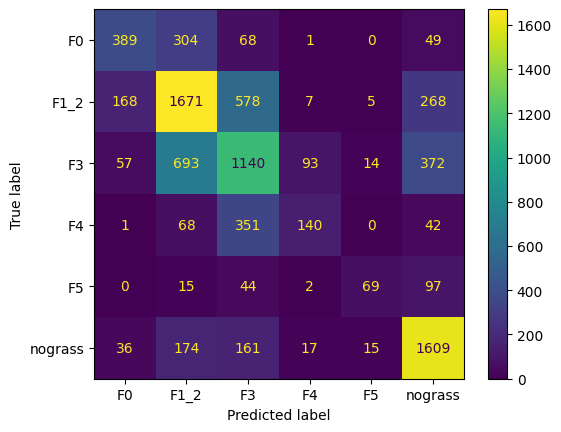

In [20]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
#pred = predictor2.predict(test_data, model='NeuralNetFastAI_BAG_L1')
#pred2 = predictor2.predict(test_data)
pred = predictor.predict(test_data, model='LightGBMXT')

cm = confusion_matrix(y_test, pred)

labels_used = np.unique(np.concatenate([y_test, pred]))
print(labels_used)


print(cm)
cm_display = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = labels_used)

cm_display.plot()
plt.show()

              precision    recall  f1-score   support

          F0       0.60      0.48      0.53       811
        F1_2       0.57      0.62      0.59      2697
          F3       0.49      0.48      0.48      2369
          F4       0.54      0.23      0.32       602
          F5       0.67      0.30      0.42       227
     nograss       0.66      0.80      0.72      2012

    accuracy                           0.58      8718
   macro avg       0.59      0.49      0.51      8718
weighted avg       0.57      0.58      0.57      8718



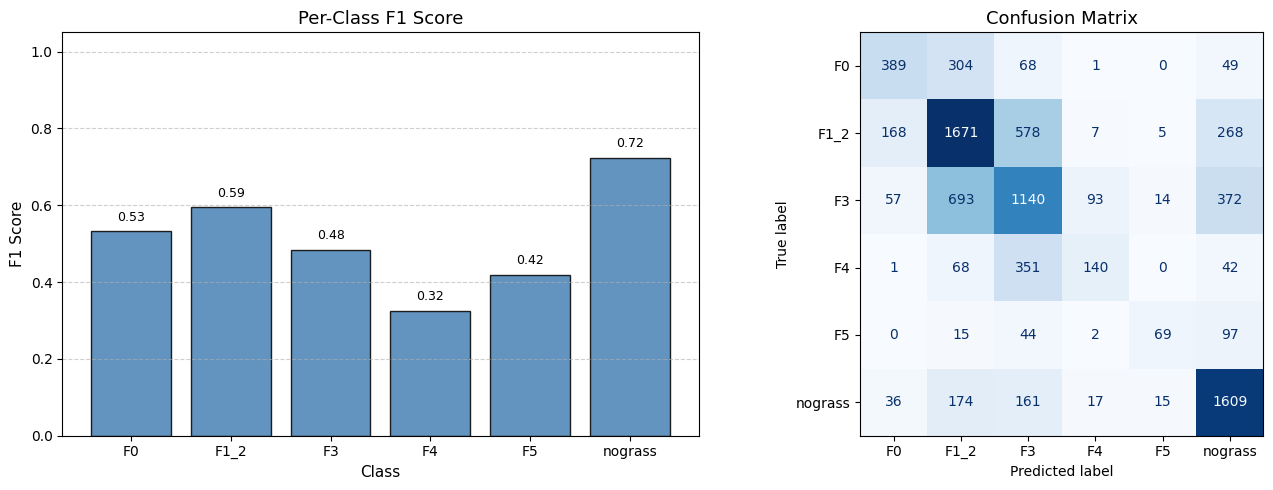

In [21]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

# --- Predictions ---
pred = predictor.predict(test_data, model='LightGBMXT')

# Keep labels sorted and consistent across metrics
labels_used = np.unique(np.concatenate([y_test, pred]))

# --- 1. Compute per-class F1 scores ---
# Setting average=None returns an array containing the F1-score for each label in `labels`
f1_per_class = f1_score(y_test, pred, labels=labels_used, average=None)

# Optional: Print numerical breakdown
print(classification_report(y_test, pred, target_names=[str(l) for l in labels_used]))

# --- 2. Plotting F1 Scores & Confusion Matrix side-by-side ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: Per-class F1 bar chart
bars = axes[0].bar([str(l) for l in labels_used], f1_per_class, color='steelblue', edgecolor='black', alpha=0.85)
axes[0].set_ylim(0, 1.05)
axes[0].set_xlabel('Class', fontsize=11)
axes[0].set_ylabel('F1 Score', fontsize=11)
axes[0].set_title('Per-Class F1 Score', fontsize=13)
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# Display score values on top of each bar
for bar, score in zip(bars, f1_per_class):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{score:.2f}",
        ha='center',
        va='bottom',
        fontsize=9
    )

# Right plot: Confusion Matrix
cm = confusion_matrix(y_test, pred, labels=labels_used)
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_used)
cm_display.plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('Confusion Matrix', fontsize=13)

plt.tight_layout()
plt.show()